<a href="https://colab.research.google.com/github/HarshMittal03/data-analytics-projects/blob/main/CAPSTON_PROJECT_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CAPSTON PROJECT 5 / DS08

# US ELECTRIC CAR REGISTRATIONS & RENEWABLE ENERGY

TASK 1.1 — DATA COLLECTION

Import libraries

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


Upload the datasets

In [ ]:
ev_file = "States_Electric_Vehicle_Registrations_2018.xlsx"
energy_file = "States_Annual_Energy_Generation_Sources_1990_2019.xlsx"
vehicle_file = "States_All_Vehicle_Registrations_2018.xlsx"
state_file = "state_codes.xlsx"


# EV registrations
ev_raw = pd.read_excel(
    ev_file,
    sheet_name="Condensed",
    header=None
)

# Energy generation
energy_raw = pd.read_excel(
    energy_file,
    sheet_name="Net_Generation_1990-2019 Final",
    header=None
)
# All vehicle registrations
vehicle_raw = pd.read_excel(
    vehicle_file,
    sheet_name="MV1",
    header=None
)

# State codes
state_codes = pd.read_excel(
    state_file
)


Check the datasets

In [ ]:
print("EV Dataset Shape:", ev_raw.shape)
print("Energy Dataset Shape:", energy_raw.shape)
print("Vehicle Dataset Shape:", vehicle_raw.shape)
print("State Codes Shape:", state_codes.shape)

EV Dataset Shape: (54, 3)
Energy Dataset Shape: (53758, 5)
Vehicle Dataset Shape: (65, 16)
State Codes Shape: (51, 2)


Display first rows

In [ ]:
print("EV DATA")
display(ev_raw.head(10))

print("\nENERGY DATA")
display(energy_raw.head(10))

print("\nVEHICLE DATA")
display(vehicle_raw.head(15))

print("\nSTATE CODE DATA")
display(state_codes.head(10))

EV DATA


,0,1,2
0,NaN,NaN,NaN
1,NaN,Electric Vehicle Registrations by State,NaN
2,NaN,State,Registration Count
3,NaN,Alabama,1450
4,NaN,Alaska,530
5,NaN,Arizona,15000
6,NaN,Arkansas,520
7,NaN,California,256800
8,NaN,Colorado,11700
9,NaN,Connecticut,4450



ENERGY DATA


,0,1,2,3,4
0,State Historical Tables for 2019\nReleased: Se...,NaN,NaN,NaN,NaN
1,YEAR,STATE,TYPE OF PRODUCER,ENERGY SOURCE,GENERATION (Megawatthours)
2,1990,AK,Total Electric Power Industry,Total,5599506
3,1990,AK,Total Electric Power Industry,Coal,510573
4,1990,AK,Total Electric Power Industry,Hydroelectric Conventional,974521
5,1990,AK,Total Electric Power Industry,Natural Gas,3466261
6,1990,AK,Total Electric Power Industry,Petroleum,497116
7,1990,AK,Total Electric Power Industry,Wind,0
8,1990,AK,Total Electric Power Industry,Wood and Wood Derived Fuels,151035
9,1990,AK,"Electric Generators, Electric Utilities",Total,4493024



VEHICLE DATA


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,STATE MOTOR-VEHICLE REGISTRATIONS - 2018,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,December 2019,(Revised February 2021),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TABLE MV-1
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,AUTOMOBILES,NaN,NaN,BUSES,NaN,NaN,TRUCKS,NaN,NaN,MOTORCYCLES,NaN,NaN,ALL MOTOR VEHICLES,NaN,NaN
8,STATE,PRIVATE AND,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,COMMERCIAL,PUBLICLY,NaN,PRIVATE AND,PUBLICLY,NaN,PRIVATE AND,PUBLICLY,NaN,PRIVATE AND,PUBLICLY,NaN,PRIVATE AND,PUBLICLY,NaN



STATE CODE DATA


,state_code,state_name
0,AK,Alaska
1,AL,Alabama
2,AR,Arkansas
3,AZ,Arizona
4,CA,California
5,CO,Colorado
6,CT,Connecticut
7,DC,District of Columbia
8,DE,Delaware
9,FL,Florida


TASK 1.2 — DATA CLEANING AND PREPROCESSING

In [ ]:
# CLEAN EV DATA

ev = pd.read_excel(
    ev_file,
    sheet_name="Condensed",
    header=2,
    usecols=[1, 2]
)


In [ ]:
# Rename columns
ev.columns = ["State", "EV_Registrations"]


In [ ]:
# Convert registrations to numeric
ev["EV_Registrations"] = pd.to_numeric(
    ev["EV_Registrations"],
    errors="coerce"
)

In [ ]:
# Clean state names
ev["State"] = ev["State"].astype(str).str.strip()

In [ ]:
# Remove missing values
ev = ev.dropna(
    subset=["State", "EV_Registrations"]
)

In [ ]:
# Remove invalid rows
ev = ev[
    ~ev["State"].str.lower().isin(["nan", "total"])
]


In [ ]:

# Remove duplicates
ev = ev.drop_duplicates()

In [ ]:
# Reset index
ev = ev.reset_index(drop=True)

print("Clean EV Dataset")
print("----------------")
print("Rows:", ev.shape[0])
print("Columns:", ev.shape[1])

display(ev.head())

Clean EV Dataset
----------------
Rows: 51
Columns: 2


,State,EV_Registrations
0,Alabama,1450
1,Alaska,530
2,Arizona,15000
3,Arkansas,520
4,California,256800


Check EV missing values

In [ ]:
print("Missing values in EV dataset:")
display(ev.isnull().sum())

Missing values in EV dataset:


,0
State,0
EV_Registrations,0


Answer

After cleaning, the EV dataset should have no important missing values in the two analysis columns.

Check EV duplicates

In [ ]:
print(
    "Number of duplicate rows:",
    ev.duplicated().sum()
)

Number of duplicate rows: 0


Clean energy dataset

In [ ]:
energy = pd.read_excel(
    energy_file,
    sheet_name="Net_Generation_1990-2019 Final",
    header=1
)

In [ ]:

# Rename columns
energy.columns = [
    "Year",
    "State",
    "Producer_Type",
    "Energy_Source",
    "Generation_MWh"
]

In [ ]:
# Convert numeric columns
energy["Year"] = pd.to_numeric(
    energy["Year"],
    errors="coerce"
)


In [ ]:
energy["Generation_MWh"] = pd.to_numeric(
    energy["Generation_MWh"],
    errors="coerce"
)

In [ ]:
# Clean text columns
energy["State"] = (
    energy["State"]
    .astype(str)
    .str.strip()
)
energy["Producer_Type"] = (
    energy["Producer_Type"]
    .astype(str)
    .str.strip()
)
energy["Energy_Source"] = (
    energy["Energy_Source"]
    .astype(str)
    .str.strip()
)

In [ ]:
# Remove invalid records
energy = energy.dropna(
    subset=[
        "Year",
        "State",
        "Energy_Source",
        "Generation_MWh"
    ]
)

In [ ]:
# Remove duplicates
energy = energy.drop_duplicates()


In [ ]:
# Reset index
energy = energy.reset_index(drop=True)

print("Clean Energy Dataset")
print("--------------------")
print("Rows:", energy.shape[0])
print("Columns:", energy.shape[1])

display(energy.head())

Clean Energy Dataset
--------------------
Rows: 53756
Columns: 5


,Year,State,Producer_Type,Energy_Source,Generation_MWh
0,1990,AK,Total Electric Power Industry,Total,5599506.0
1,1990,AK,Total Electric Power Industry,Coal,510573.0
2,1990,AK,Total Electric Power Industry,Hydroelectric Conventional,974521.0
3,1990,AK,Total Electric Power Industry,Natural Gas,3466261.0
4,1990,AK,Total Electric Power Industry,Petroleum,497116.0


Energy data quality check

In [ ]:
print("Missing values:")
display(energy.isnull().sum())

print("\nDuplicate rows:")
print(energy.duplicated().sum())

print("\nData types:")
display(energy.dtypes)

Missing values:


,0
Year,0
State,0
Producer_Type,0
Energy_Source,0
Generation_MWh,0



Duplicate rows:
0

Data types:


,0
Year,int64
State,object
Producer_Type,object
Energy_Source,object
Generation_MWh,float64


Clean all vehicle dataset

In [ ]:
vehicle = pd.read_excel(
    vehicle_file,
    sheet_name="MV1",
    header=8
)

display(vehicle.head())

,STATE,PRIVATE AND,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,NaN,COMMERCIAL,PUBLICLY,NaN,PRIVATE AND,PUBLICLY,NaN,PRIVATE AND,PUBLICLY,NaN,PRIVATE AND,PUBLICLY,NaN,PRIVATE AND,PUBLICLY,NaN
1,NaN,(INCLUDING,OWNED (1),TOTAL,COMMERCIAL,OWNED (1),TOTAL,COMMERCIAL,OWNED (1),TOTAL,COMMERCIAL,OWNED (1),TOTAL,COMMERCIAL,OWNED (1),TOTAL
2,NaN,TAXICABS),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Alabama,2116626,44586,2161212,5633.635236,132.974093,5766.609329,2955947,67261.40963,3023208.40963,109060,952.135108,110012.135108,5187266.635236,112932.518832,5300199.154068
4,Alaska,179131,4139,183270,7856,617.322626,8473.322626,563583,16807.236526,580390.236526,31542,8,31550,782112,21571.559152,803683.559152


Read vehicle totals directly

In [ ]:

vehicle_raw2 = pd.read_excel(
    vehicle_file,
    sheet_name="MV1",
    header=None
)

vehicle_clean = vehicle_raw2.iloc[10:].copy()

vehicle_clean = vehicle_clean.rename(
    columns={vehicle_clean.columns[0]: "State"}
)


vehicle_clean["State"] = (
    vehicle_clean["State"]
    .astype(str)
    .str.strip()
)

vehicle_clean = vehicle_clean[
    ~vehicle_clean["State"].str.lower().isin(
        ["nan", "total"]
    )
]

vehicle_clean = vehicle_clean.reset_index(drop=True)

print("Vehicle records:")
display(vehicle_clean.head())

Vehicle records:


,State,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,Alabama,2116626,44586,2161212,5633.635236,132.974093,5766.609329,2955947,67261.40963,3023208.40963,109060,952.135108,110012.135108,5187266.635236,112932.518832,5300199.154068
1,Alaska,179131,4139,183270,7856,617.322626,8473.322626,563583,16807.236526,580390.236526,31542,8,31550,782112,21571.559152,803683.559152
2,Arizona,2372443,19329,2391772,1391.050584,6958.088141,8349.138725,3196426,39491.535925,3235917.535925,170271,3,170274,5740531.050584,65781.624066,5806312.674649
3,Arkansas,908561,12600,921161,11290.281712,715.885705,12006.167417,1765374,27477.128806,1792851.128806,91127,0,91127,2776352.281712,40793.01451,2817145.296223
4,California,14820833,244994,15065827,34437,65255.244456,99692.244456,14739522,294442.632872,15033964.632872,808889,13955,822844,30403681,618646.877329,31022327.877329


TASK 2.1 — EXPLORATORY DATA ANALYSIS

EV basic information

In [ ]:

print("EV Dataset Information")
print("=======================")

print("Number of states:", ev["State"].nunique())

print(
    "Total EV registrations:",
    ev["EV_Registrations"].sum()
)

print(
    "Average EV registrations:",
    ev["EV_Registrations"].mean()
)

print(
    "Median EV registrations:",
    ev["EV_Registrations"].median()
)

EV Dataset Information
Number of states: 51
Total EV registrations: 543610
Average EV registrations: 10659.019607843138
Median EV registrations: 3450.0


EV descriptive statistics

In [ ]:
display(
    ev["EV_Registrations"].describe()
)

,EV_Registrations
count,51.000000
mean,10659.019608
std,35793.028330
min,170.000000
25%,1015.000000
50%,3450.000000
75%,8225.000000
max,256800.000000


Highest EV states

In [ ]:
top_states = (
    ev.sort_values(
        "EV_Registrations",
        ascending=False
    )
    .head(10)
)

display(top_states)

,State,EV_Registrations
4,California,256800
47,Washington,28400
9,Florida,25200
43,Texas,22600
32,New York,16600
10,Georgia,15300
2,Arizona,15000
37,Oregon,12400
13,Illinois,12400
30,New Jersey,12100


Lowest EV states

In [ ]:
lowest_states = (
    ev.sort_values(
        "EV_Registrations",
        ascending=True
    )
    .head(10)
)

display(lowest_states)

,State,EV_Registrations
50,Wyoming,170
34,North Dakota,170
48,West Virginia,230
41,South Dakota,260
24,Mississippi,390
26,Montana,500
3,Arkansas,520
1,Alaska,530
39,Rhode Island,600
7,Delaware,720


Energy Dataset

Energy data overview

In [ ]:

print("\nNumber of states:")
print(energy["State"].nunique())

print("\nEnergy sources:")
print(
    energy["Energy_Source"]
    .nunique()
)

display(
    energy["Energy_Source"]
    .value_counts()
)


Number of states:
54

Energy sources:
14


,count
Energy_Source,
Total,8339
Natural Gas,7454
Petroleum,7171
Coal,5512
Other Biomass,4958
Hydroelectric Conventional,4552
Wood and Wood Derived Fuels,3424
Other,3130
Other Gases,2116


Energy descriptive statistics

In [ ]:
display(
    energy["Generation_MWh"].describe()
)

,Generation_MWh
count,5.375600e+04
mean,1.693131e+07
std,1.309890e+08
min,-8.823445e+06
25%,2.684825e+04
50%,3.279665e+05
75%,3.405300e+06
max,4.178277e+09


TASK 2.2 — VISUALIZATION USING MATPLOTLIB AND SEABORN

Visualization 1 — EV registrations distribution

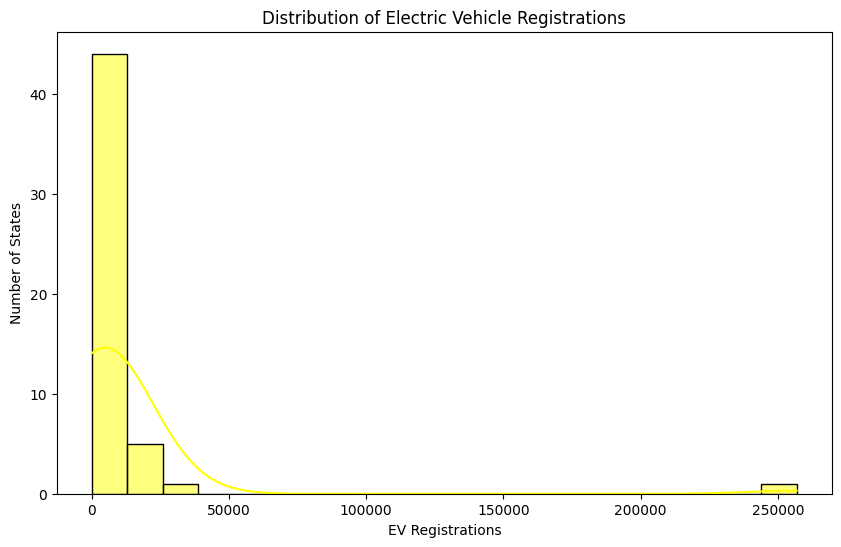

In [ ]:

plt.figure(figsize=(10,6))

sns.histplot(
    ev["EV_Registrations"],
    bins=20,
    kde=True,color="yellow")

plt.title(
    "Distribution of Electric Vehicle Registrations"
)

plt.xlabel(
    "EV Registrations"
)

plt.ylabel(
    "Number of States"
)

plt.show()

Answer

This visualization shows the distribution of EV registrations across states.

Visualization 2 — EV boxplot

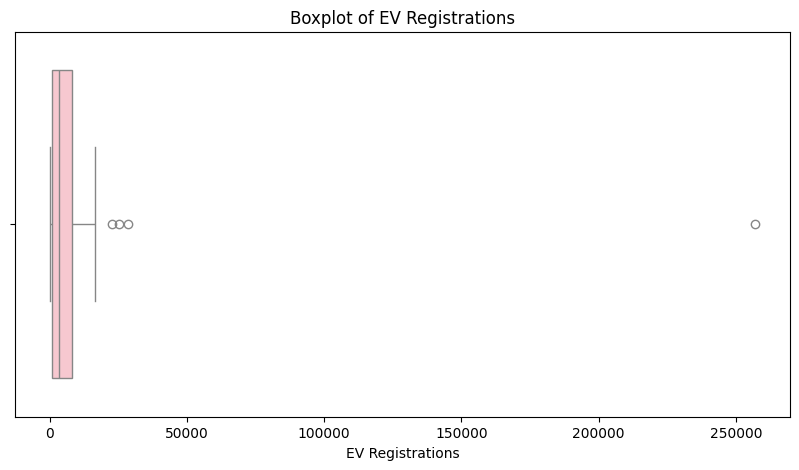

In [ ]:

plt.figure(figsize=(10,5))

sns.boxplot(
    x=ev["EV_Registrations"],color="pink"
)

plt.title(
    "Boxplot of EV Registrations"
)

plt.xlabel(
    "EV Registrations"
)

plt.show()

Visualization 3 — Top 10 EV states

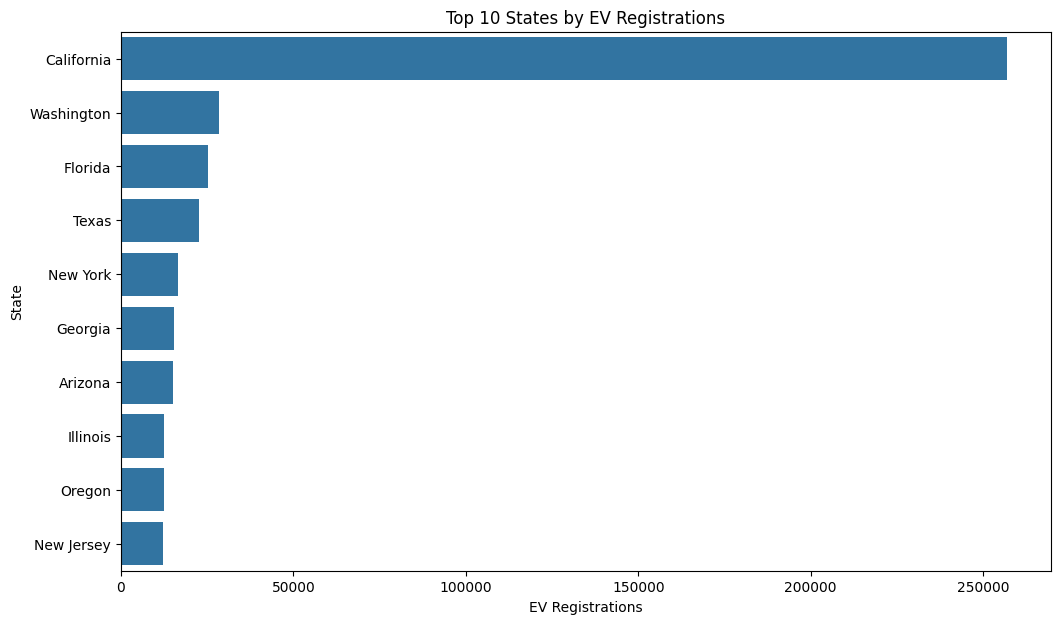

In [ ]:

top10 = ev.nlargest(
    10,
    "EV_Registrations"
)

plt.figure(figsize=(12,7))

sns.barplot(
    data=top10,
    x="EV_Registrations",
    y="State"
)

plt.title(
    "Top 10 States by EV Registrations"
)

plt.xlabel(
    "EV Registrations"
)

plt.ylabel(
    "State"
)

plt.show()

Visualization 4 — Bottom 10 EV states

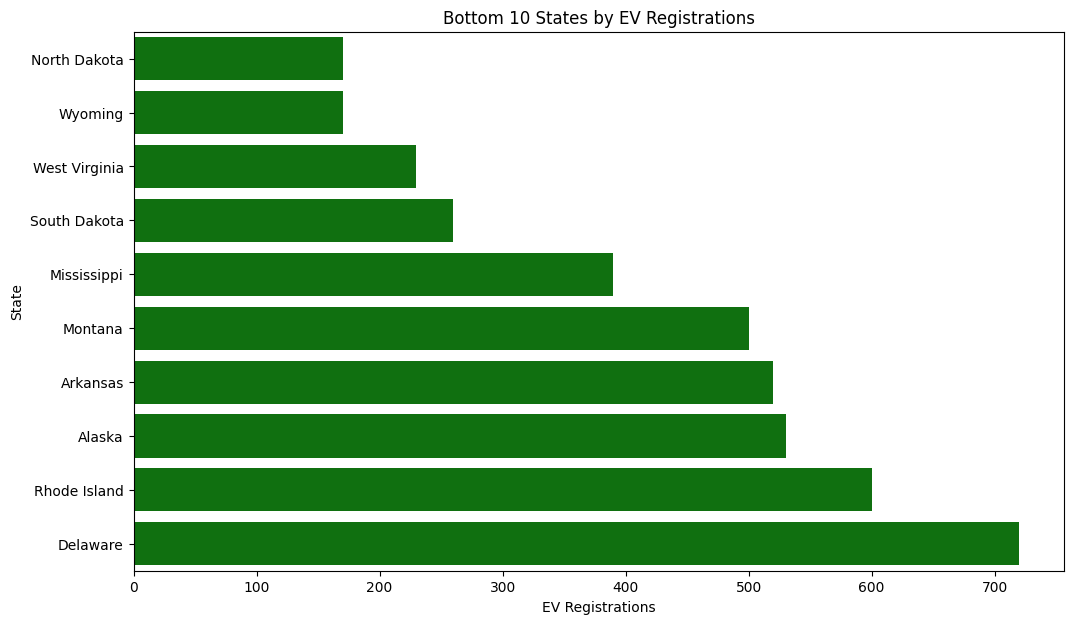

In [ ]:

bottom10 = ev.nsmallest(
    10,
    "EV_Registrations"
)

plt.figure(figsize=(12,7))

sns.barplot(
    data=bottom10,
    x="EV_Registrations",
    y="State",color="green"
)

plt.title(
    "Bottom 10 States by EV Registrations"
)

plt.xlabel(
    "EV Registrations"
)

plt.ylabel(
    "State"
)

plt.show()

Visualization 5 — Total generation by source

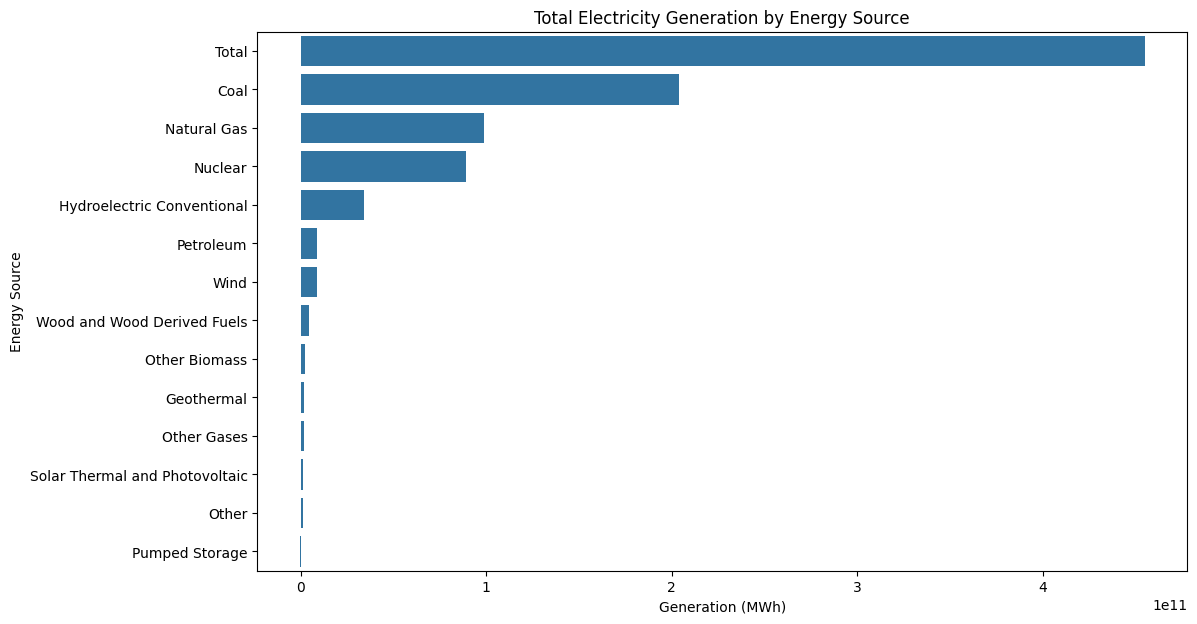

In [ ]:
energy_summary = (
    energy
    .groupby("Energy_Source")["Generation_MWh"]
    .sum()
    .sort_values(ascending=False)
)

top_energy = (
    energy_summary
    .head(15)
)

plt.figure(figsize=(12,7))

sns.barplot(
    x=top_energy.values,
    y=top_energy.index
)

plt.title(
    "Total Electricity Generation by Energy Source"
)

plt.xlabel(
    "Generation (MWh)"
)

plt.ylabel(
    "Energy Source"
)

plt.show()

TASK 3 — CORRELATION & RELATIONSHIP ANALYSIS


Task 3.1 — Merge EV and All Vehicle Registration Data

In [ ]:
# Merge EV registrations with all vehicle registrations

ev_vehicle = pd.merge(
    ev,
    vehicle_clean,
    on="State",
    how="inner"
)

print("Merged Dataset Shape:", ev_vehicle.shape)

display(ev_vehicle.head())

Merged Dataset Shape: (46, 17)


,State,EV_Registrations,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,Alabama,1450,2116626,44586,2161212,5633.635236,132.974093,5766.609329,2955947,67261.40963,3023208.40963,109060,952.135108,110012.135108,5187266.635236,112932.518832,5300199.154068
1,Alaska,530,179131,4139,183270,7856,617.322626,8473.322626,563583,16807.236526,580390.236526,31542,8,31550,782112,21571.559152,803683.559152
2,Arizona,15000,2372443,19329,2391772,1391.050584,6958.088141,8349.138725,3196426,39491.535925,3235917.535925,170271,3,170274,5740531.050584,65781.624066,5806312.674649
3,Arkansas,520,908561,12600,921161,11290.281712,715.885705,12006.167417,1765374,27477.128806,1792851.128806,91127,0,91127,2776352.281712,40793.01451,2817145.296223
4,California,256800,14820833,244994,15065827,34437,65255.244456,99692.244456,14739522,294442.632872,15033964.632872,808889,13955,822844,30403681,618646.877329,31022327.877329


Check missing values

In [ ]:
ev_vehicle.isnull().sum()

,0
State,0
EV_Registrations,0
1,0
2,0
3,0
4,0
5,0
6,0
7,0
8,0


Task 3.2 — EV Share of Total Vehicles

In [ ]:

ev_vehicle = ev_vehicle.rename(columns={3: "All_Motor_Vehicles"})

ev_vehicle["EV_Share_Percent"] = (
    ev_vehicle["EV_Registrations"] /
    ev_vehicle["All_Motor_Vehicles"]
) * 100

display(
    ev_vehicle[
        ["State", "EV_Registrations", "All_Motor_Vehicles", "EV_Share_Percent"]
    ].sort_values("EV_Share_Percent", ascending=False).head(10)
)

,State,EV_Registrations,All_Motor_Vehicles,EV_Share_Percent
4,California,256800,15065827,1.70452
10,Hawaii,6590,509492,1.293445
43,Washington,28400,2964939,0.957861
33,Oregon,12400,1488623,0.832985
5,Colorado,11700,1798177,0.650659
2,Arizona,15000,2391772,0.62715
40,Utah,5220,937421,0.556847
41,Vermont,1060,218302,0.485566
25,Nevada,4810,1073760,0.447959
27,New Jersey,12100,2754253,0.439321


Visualization

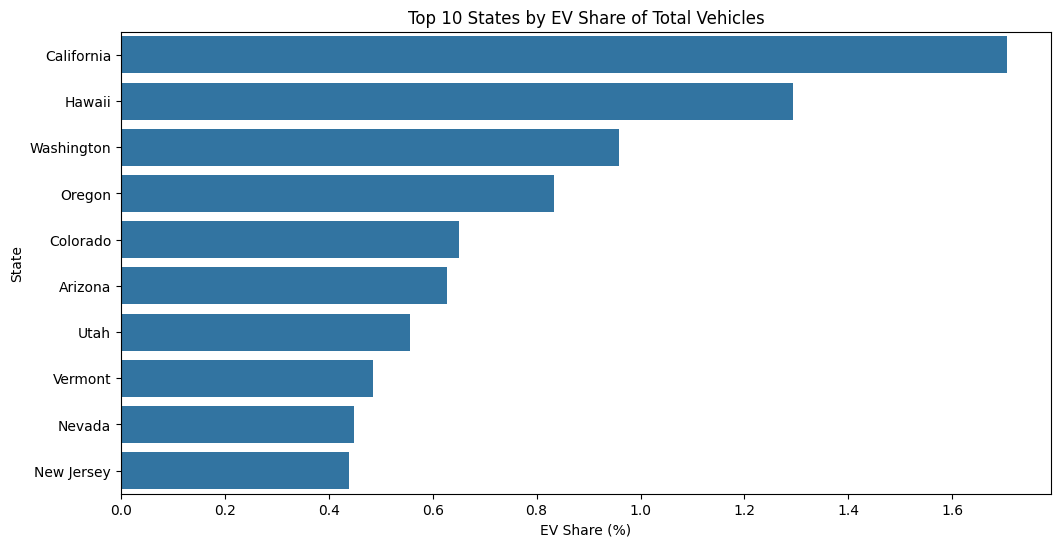

In [ ]:
plt.figure(figsize=(12,6))

top_ev_share = ev_vehicle.sort_values(
    "EV_Share_Percent",
    ascending=False
).head(10)

sns.barplot(
    data=top_ev_share,
    x="EV_Share_Percent",
    y="State"
)

plt.title("Top 10 States by EV Share of Total Vehicles")
plt.xlabel("EV Share (%)")
plt.ylabel("State")
plt.show()

TASK 3.3 — Correlation Matrix

In [ ]:
ev_vehicle = ev_vehicle.rename(columns={
    4: "Automobiles",
    5: "Buses",
    6: "Trucks",
    7: "Motorcycles"
})

correlation_data = ev_vehicle[
    [
        "EV_Registrations",
        "Automobiles",
        "Buses",
        "Trucks",
        "Motorcycles",
        "All_Motor_Vehicles"
    ]
]

correlation_matrix = correlation_data.corr()

print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,EV_Registrations,Automobiles,Buses,Trucks,Motorcycles,All_Motor_Vehicles
EV_Registrations,1.000000,0.291678,0.706405,0.630259,0.680719,0.809894
Automobiles,0.291678,1.000000,0.192366,0.801157,0.569755,0.565526
Buses,0.706405,0.192366,1.000000,0.741392,0.839053,0.845052
Trucks,0.630259,0.801157,0.741392,1.000000,0.901315,0.902081
Motorcycles,0.680719,0.569755,0.839053,0.901315,1.000000,0.967823
All_Motor_Vehicles,0.809894,0.565526,0.845052,0.902081,0.967823,1.000000


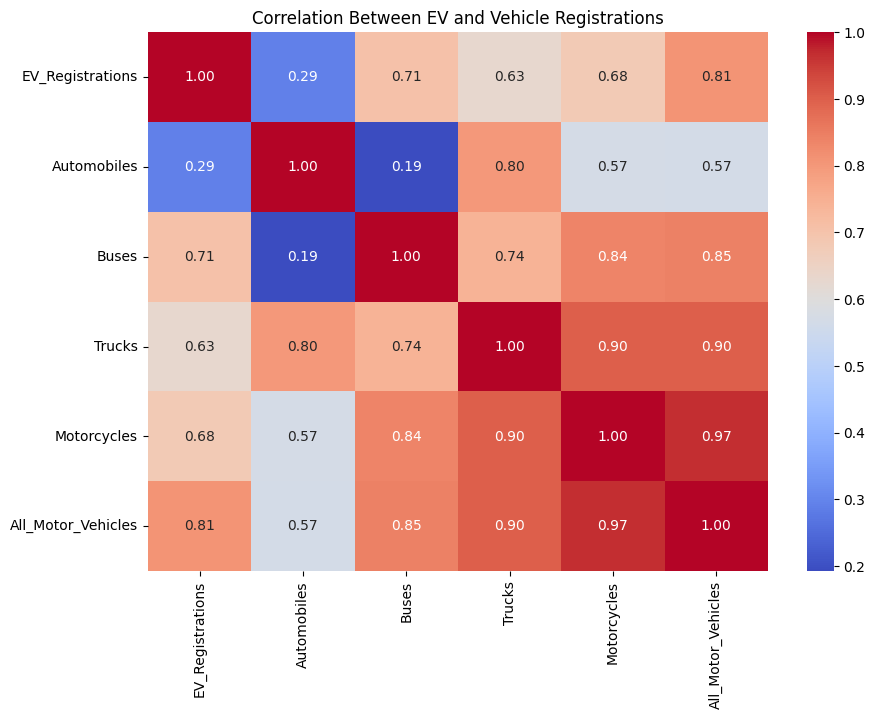

In [ ]:
plt.figure(figsize=(10,7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between EV and Vehicle Registrations")
plt.show()

TASK 3.4 — EV Registrations vs Total Vehicles

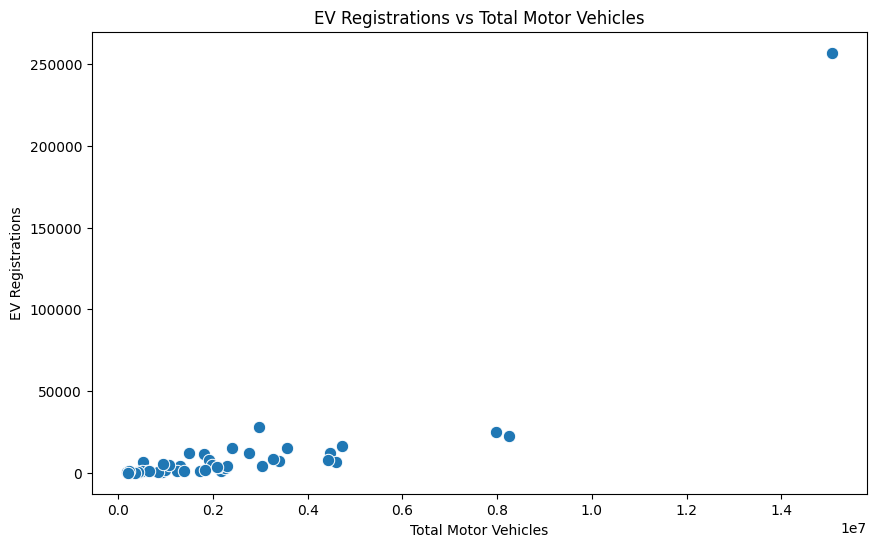

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=ev_vehicle,
    x="All_Motor_Vehicles",
    y="EV_Registrations",
    s=80
)

plt.title("EV Registrations vs Total Motor Vehicles")
plt.xlabel("Total Motor Vehicles")
plt.ylabel("EV Registrations")
plt.show()

Add regression line

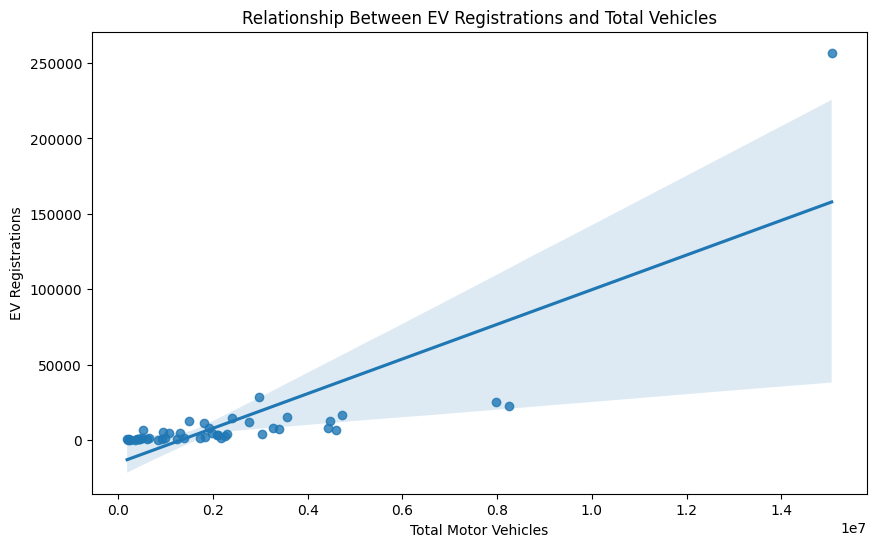

In [ ]:
plt.figure(figsize=(10,6))

# Ensure the 'All_Motor_Vehicles' column is numeric
ev_vehicle['All_Motor_Vehicles'] = pd.to_numeric(ev_vehicle['All_Motor_Vehicles'], errors='coerce')

sns.regplot(
    data=ev_vehicle,
    x="All_Motor_Vehicles",
    y="EV_Registrations"
)

plt.title("Relationship Between EV Registrations and Total Vehicles")
plt.xlabel("Total Motor Vehicles")
plt.ylabel("EV Registrations")
plt.show()

TASK 3.5 — States With Highest EV Registrations

In [ ]:
top_15_ev = ev.sort_values(
    "EV_Registrations",
    ascending=False
).head(15)

display(top_15_ev)

,State,EV_Registrations
4,California,256800
47,Washington,28400
9,Florida,25200
43,Texas,22600
32,New York,16600
10,Georgia,15300
2,Arizona,15000
37,Oregon,12400
13,Illinois,12400
30,New Jersey,12100


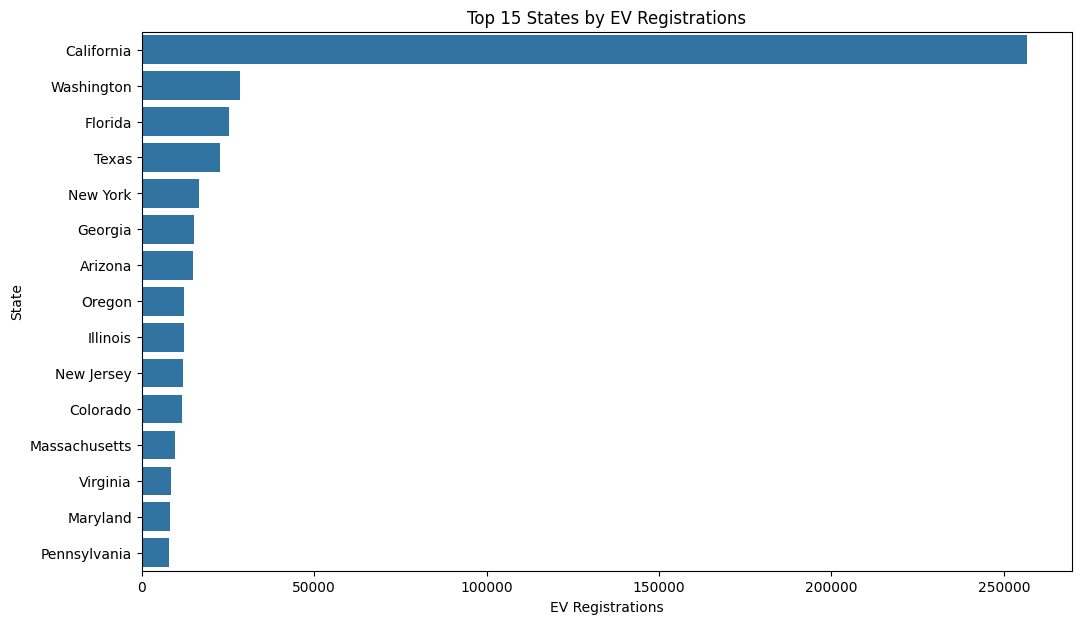

In [ ]:
plt.figure(figsize=(12,7))

sns.barplot(
    data=top_15_ev,
    x="EV_Registrations",
    y="State"
)

plt.title("Top 15 States by EV Registrations")
plt.xlabel("EV Registrations")
plt.ylabel("State")
plt.show()

TASK 4 — RENEWABLE ENERGY ANALYSIS

Task 4.1 — Identify Renewable Energy Sources

For this project, we can analyze these renewable sources available in the dataset:

Hydroelectric Conventional

Wind

Wood and Wood Derived Fuels

Other Biomass

Geothermal

Solar Thermal and Photovoltaic

In [ ]:
renewable_sources = [
    "Hydroelectric Conventional",
    "Wind",
    "Wood and Wood Derived Fuels",
    "Other Biomass",
    "Geothermal",
    "Solar Thermal and Photovoltaic"
]

renewable_energy = energy[
    energy["Energy_Source"].isin(renewable_sources)
].copy()

display(renewable_energy.head())

,Year,State,Producer_Type,Energy_Source,Generation_MWh
2,1990,AK,Total Electric Power Industry,Hydroelectric Conventional,974521.0
5,1990,AK,Total Electric Power Industry,Wind,0.0
6,1990,AK,Total Electric Power Industry,Wood and Wood Derived Fuels,151035.0
9,1990,AK,"Electric Generators, Electric Utilities",Hydroelectric Conventional,974521.0
12,1990,AK,"Electric Generators, Electric Utilities",Wind,0.0


TASK 4.2 — Total Renewable Generation by Source

In [ ]:
renewable_by_source = (
    renewable_energy
    .groupby("Energy_Source")["Generation_MWh"]
    .sum()
    .sort_values(ascending=False)
)

display(renewable_by_source)

,Generation_MWh
Energy_Source,
Hydroelectric Conventional,3.380272e+10
Wind,8.936417e+09
Wood and Wood Derived Fuels,4.549361e+09
Other Biomass,2.263408e+09
Geothermal,1.816247e+09
Solar Thermal and Photovoltaic,1.179676e+09


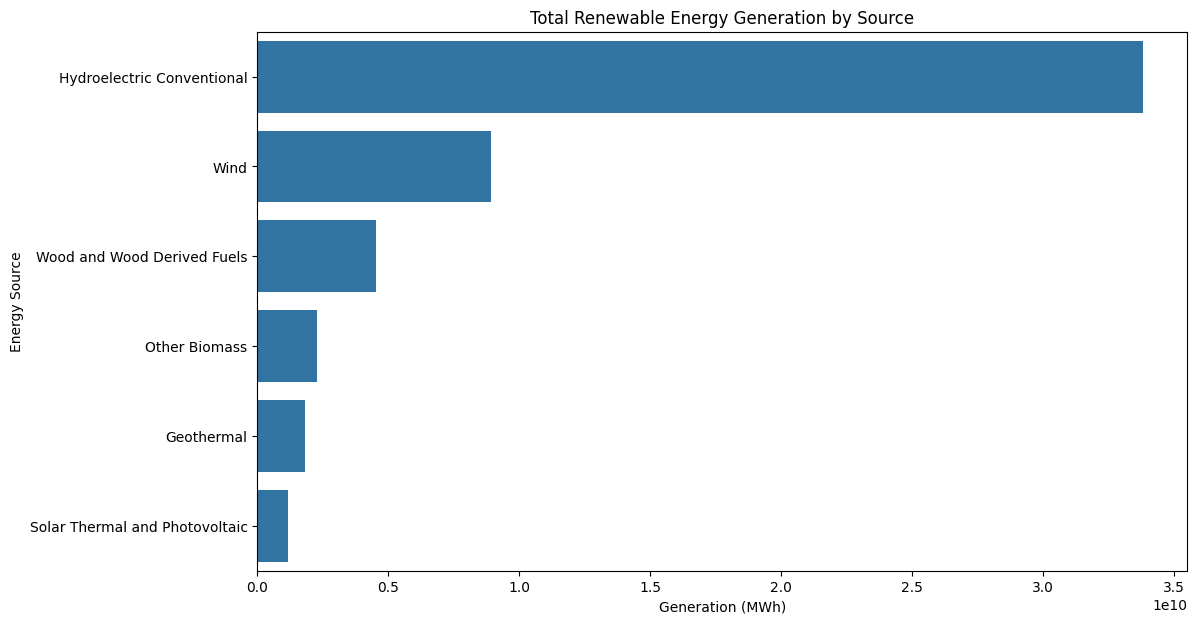

In [ ]:
plt.figure(figsize=(12,7))

sns.barplot(
    x=renewable_by_source.values,
    y=renewable_by_source.index
)

plt.title("Total Renewable Energy Generation by Source")
plt.xlabel("Generation (MWh)")
plt.ylabel("Energy Source")
plt.show()

TASK 4.3 — Renewable Energy Trend Over Years

In [ ]:
renewable_yearly = (
    renewable_energy
    .groupby("Year")["Generation_MWh"]
    .sum()
    .reset_index()
)

display(renewable_yearly.head())

,Year,Generation_MWh
0,1990,1.428952e+09
1,1991,1.431094e+09
2,1992,1.307431e+09
3,1993,1.426829e+09
4,1994,1.346644e+09


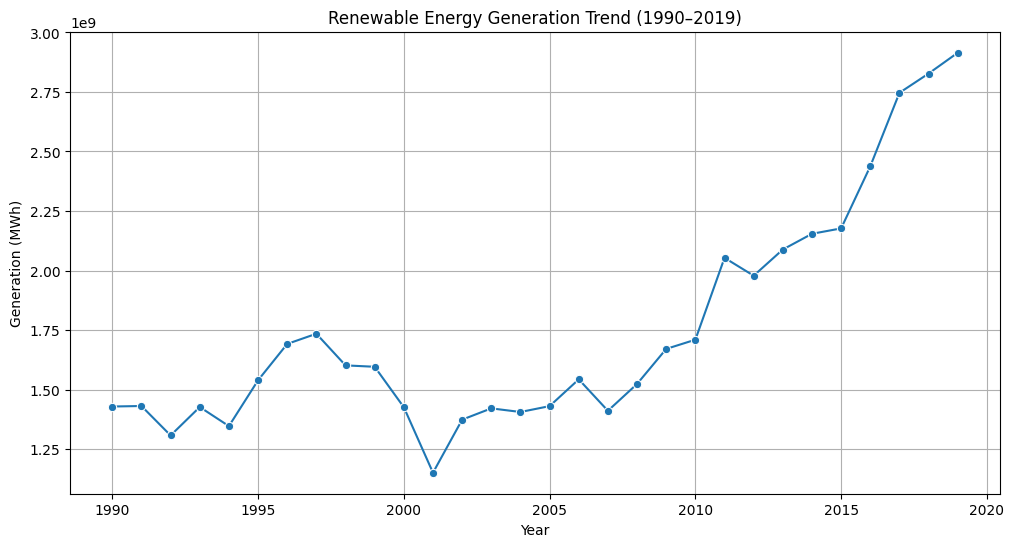

In [ ]:
plt.figure(figsize=(12,6))

sns.lineplot(
    data=renewable_yearly,
    x="Year",
    y="Generation_MWh",
    marker="o"
)

plt.title("Renewable Energy Generation Trend (1990–2019)")
plt.xlabel("Year")
plt.ylabel("Generation (MWh)")
plt.grid(True)
plt.show()

TASK 4.4 — Renewable Energy by Source Over Time

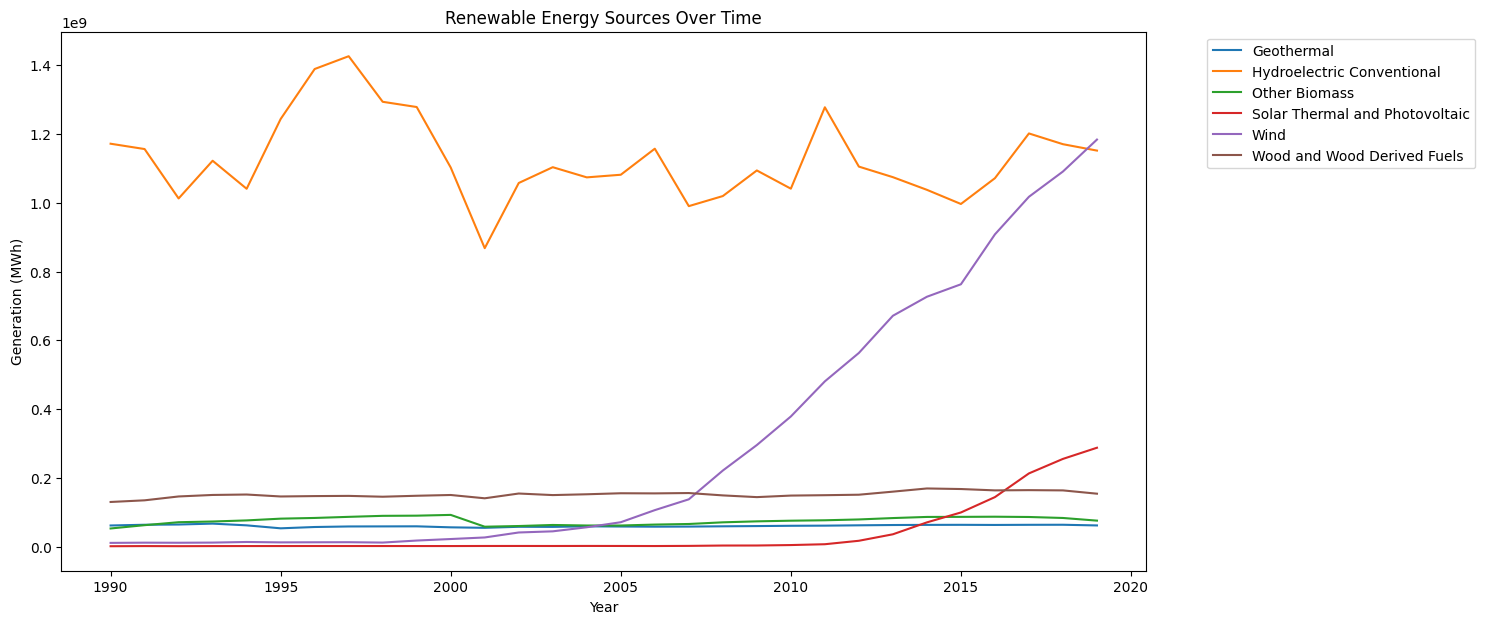

In [ ]:
renewable_source_year = (
    renewable_energy
    .groupby(["Year", "Energy_Source"])["Generation_MWh"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(14,7))

sns.lineplot(
    data=renewable_source_year,
    x="Year",
    y="Generation_MWh",
    hue="Energy_Source"
)

plt.title("Renewable Energy Sources Over Time")
plt.xlabel("Year")
plt.ylabel("Generation (MWh)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

TASK 4.5 — Wind Energy Trend

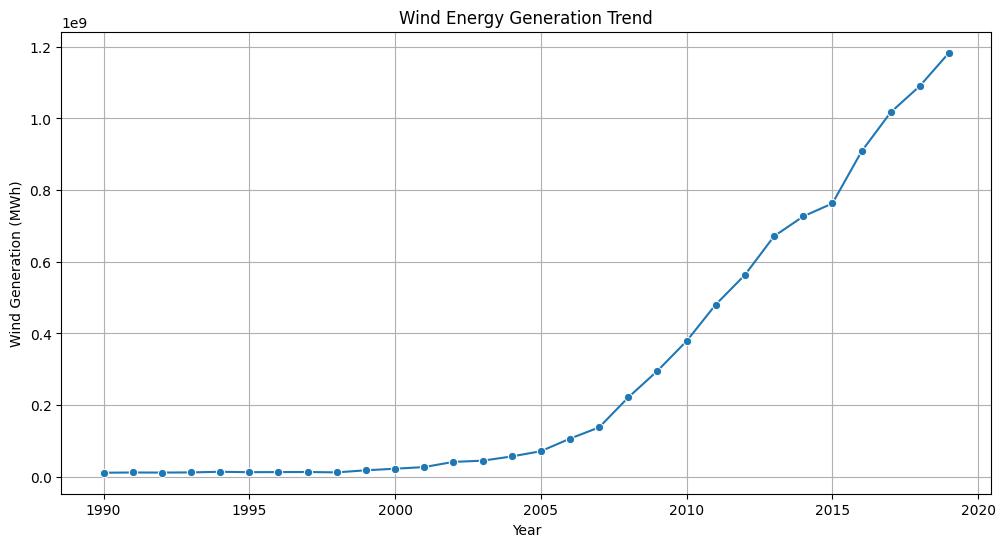

In [ ]:
wind = renewable_energy[
    renewable_energy["Energy_Source"] == "Wind"
]

wind_yearly = (
    wind.groupby("Year")["Generation_MWh"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12,6))

sns.lineplot(
    data=wind_yearly,
    x="Year",
    y="Generation_MWh",
    marker="o"
)

plt.title("Wind Energy Generation Trend")
plt.xlabel("Year")
plt.ylabel("Wind Generation (MWh)")
plt.grid(True)
plt.show()

TASK 4.6 — Solar Energy Trend

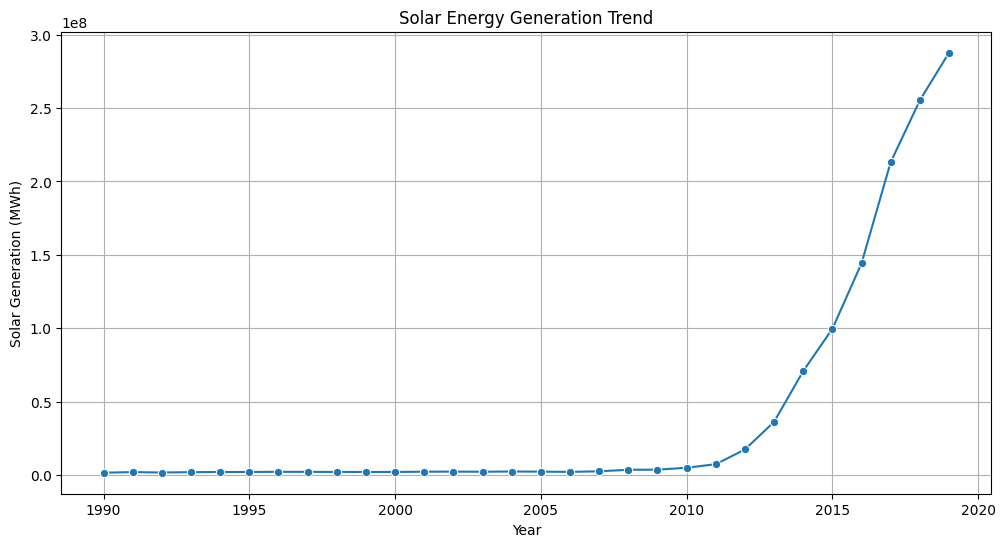

In [ ]:
solar = renewable_energy[
    renewable_energy["Energy_Source"] ==
    "Solar Thermal and Photovoltaic"
]

solar_yearly = (
    solar.groupby("Year")["Generation_MWh"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12,6))

sns.lineplot(
    data=solar_yearly,
    x="Year",
    y="Generation_MWh",
    marker="o"
)

plt.title("Solar Energy Generation Trend")
plt.xlabel("Year")
plt.ylabel("Solar Generation (MWh)")
plt.grid(True)
plt.show()

TASK 4.7 — Renewable Energy by State

In [ ]:
renewable_state = (
    renewable_energy
    .groupby("State")["Generation_MWh"]
    .sum()
    .sort_values(ascending=False)
)

display(renewable_state.head(15))

,Generation_MWh
State,
US-TOTAL,1.661195e+10
US-Total,9.661967e+09
WA,4.987962e+09
CA,3.750149e+09
OR,2.375338e+09
NY,1.832774e+09
TX,1.303731e+09
AL,7.743051e+08
ID,6.823129e+08


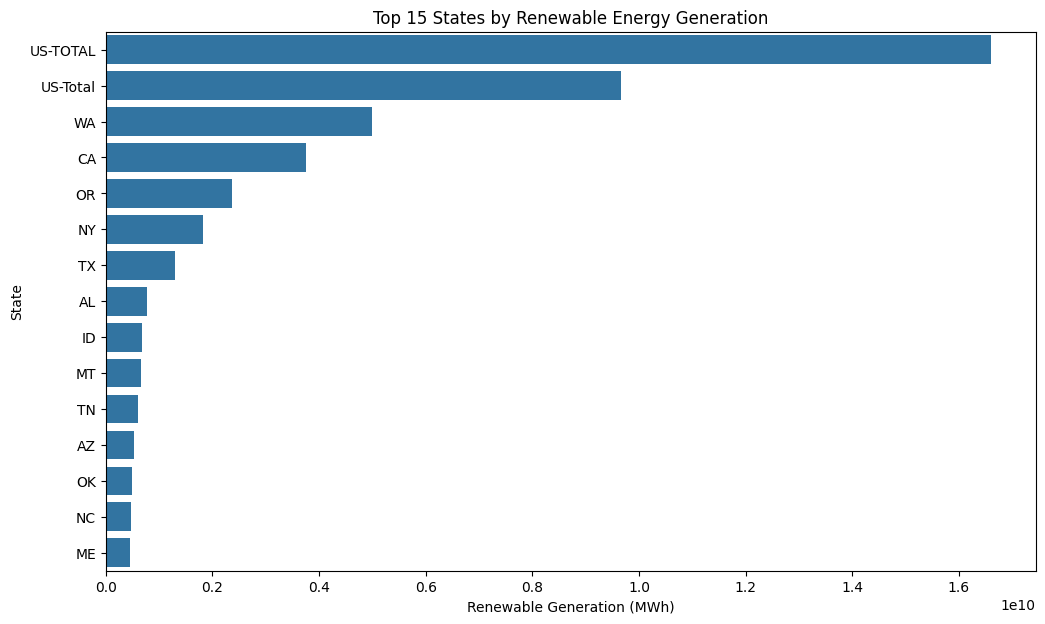

In [ ]:
top_renewable_states = renewable_state.head(15)

plt.figure(figsize=(12,7))

sns.barplot(
    x=top_renewable_states.values,
    y=top_renewable_states.index
)

plt.title("Top 15 States by Renewable Energy Generation")
plt.xlabel("Renewable Generation (MWh)")
plt.ylabel("State")
plt.show()

TASK 5 — EV AND RENEWABLE ENERGY COMPARISON


Task 5.1 — Renewable Energy by State

In [ ]:
renewable_state_df = renewable_state.reset_index()

renewable_state_df.columns = [
    "State",
    "Renewable_Generation_MWh"
]

display(renewable_state_df.head())

,State,Renewable_Generation_MWh
0,US-TOTAL,1.661195e+10
1,US-Total,9.661967e+09
2,WA,4.987962e+09
3,CA,3.750149e+09
4,OR,2.375338e+09


Task 5.2 — Merge EV Data With Renewable Energy

In [ ]:
ev_renewable = pd.merge(
    ev,
    renewable_state_df,
    on="State",
    how="inner"
)

display(ev_renewable.head())

print("Dataset Shape:", ev_renewable.shape)

,State,EV_Registrations,Renewable_Generation_MWh


Dataset Shape: (0, 3)


TASK 5.3 — EV Registrations vs Renewable Generation

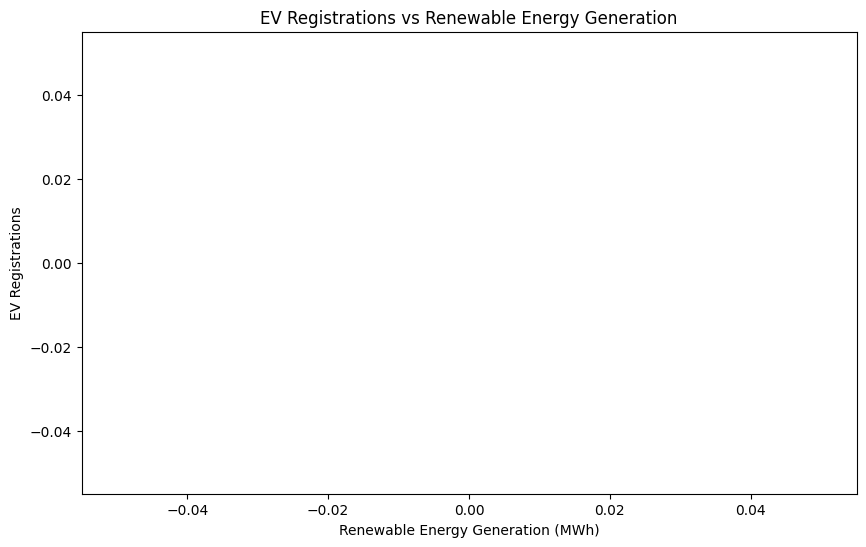

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=ev_renewable,
    x="Renewable_Generation_MWh",
    y="EV_Registrations",
    s=80
)

plt.title("EV Registrations vs Renewable Energy Generation")
plt.xlabel("Renewable Energy Generation (MWh)")
plt.ylabel("EV Registrations")
plt.show()

TASK 5.4 — Correlation Between EVs and Renewable Energy

In [ ]:
ev_renewable[
    ["EV_Registrations", "Renewable_Generation_MWh"]
].corr()

,EV_Registrations,Renewable_Generation_MWh
EV_Registrations,NaN,NaN
Renewable_Generation_MWh,NaN,NaN


/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


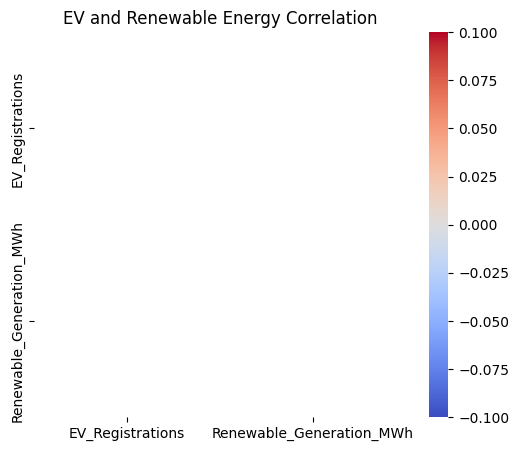

In [ ]:
plt.figure(figsize=(6,5))

sns.heatmap(
    ev_renewable[
        ["EV_Registrations", "Renewable_Generation_MWh"]
    ].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("EV and Renewable Energy Correlation")
plt.show()

TASK 6 — ENERGY SOURCE COMPARISON


Task 6.1 — Compare Coal, Natural Gas, Wind and Solar

In [ ]:
selected_sources = [
    "Coal",
    "Natural Gas",
    "Wind",
    "Solar Thermal and Photovoltaic"
]

selected_energy = energy[
    energy["Energy_Source"].isin(selected_sources)
]

source_year = (
    selected_energy
    .groupby(["Year", "Energy_Source"])["Generation_MWh"]
    .sum()
    .reset_index()
)

display(source_year.head())

,Year,Energy_Source,Generation_MWh
0,1990,Coal,6.376046e+09
1,1990,Natural Gas,1.491061e+09
2,1990,Solar Thermal and Photovoltaic,1.468348e+06
3,1990,Wind,1.115440e+07
4,1991,Coal,6.362491e+09


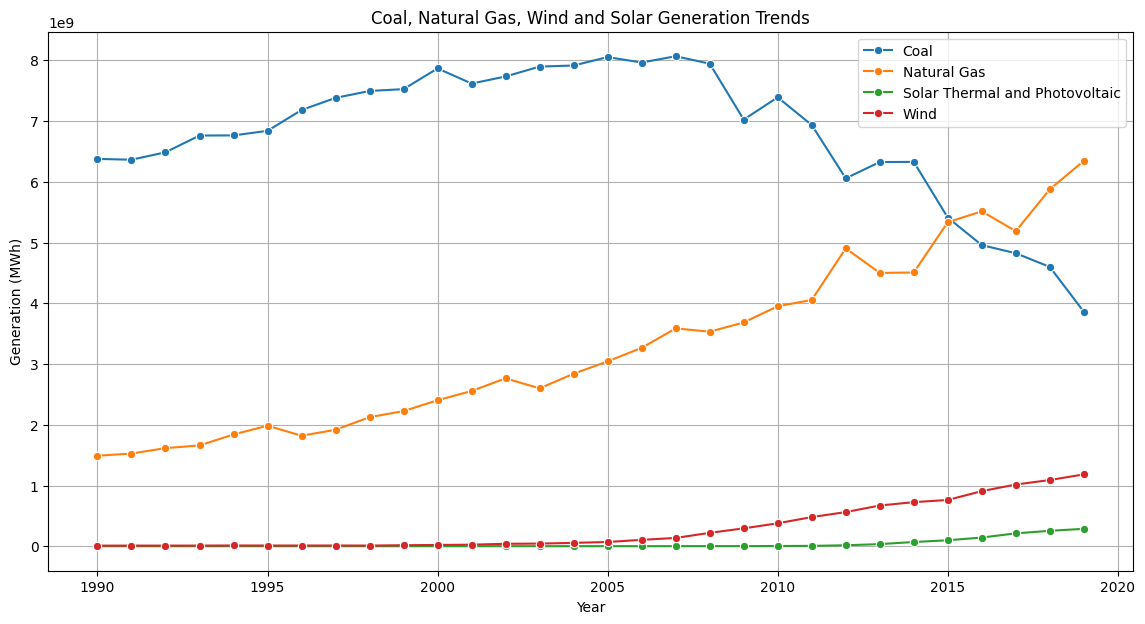

In [ ]:
plt.figure(figsize=(14,7))

sns.lineplot(
    data=source_year,
    x="Year",
    y="Generation_MWh",
    hue="Energy_Source",
    marker="o"
)

plt.title("Coal, Natural Gas, Wind and Solar Generation Trends")
plt.xlabel("Year")
plt.ylabel("Generation (MWh)")
plt.legend()
plt.grid(True)
plt.show()

TASK 6.2 — Total Generation by Energy Source

In [ ]:
total_source_generation = (
    energy
    .groupby("Energy_Source")["Generation_MWh"]
    .sum()
    .sort_values(ascending=False)
)

display(total_source_generation)

,Generation_MWh
Energy_Source,
Total,4.550797e+11
Coal,2.039088e+11
Natural Gas,9.865095e+10
Nuclear,8.900162e+10
Hydroelectric Conventional,3.380272e+10
Petroleum,8.936816e+09
Wind,8.936417e+09
Wood and Wood Derived Fuels,4.549361e+09
Other Biomass,2.263408e+09


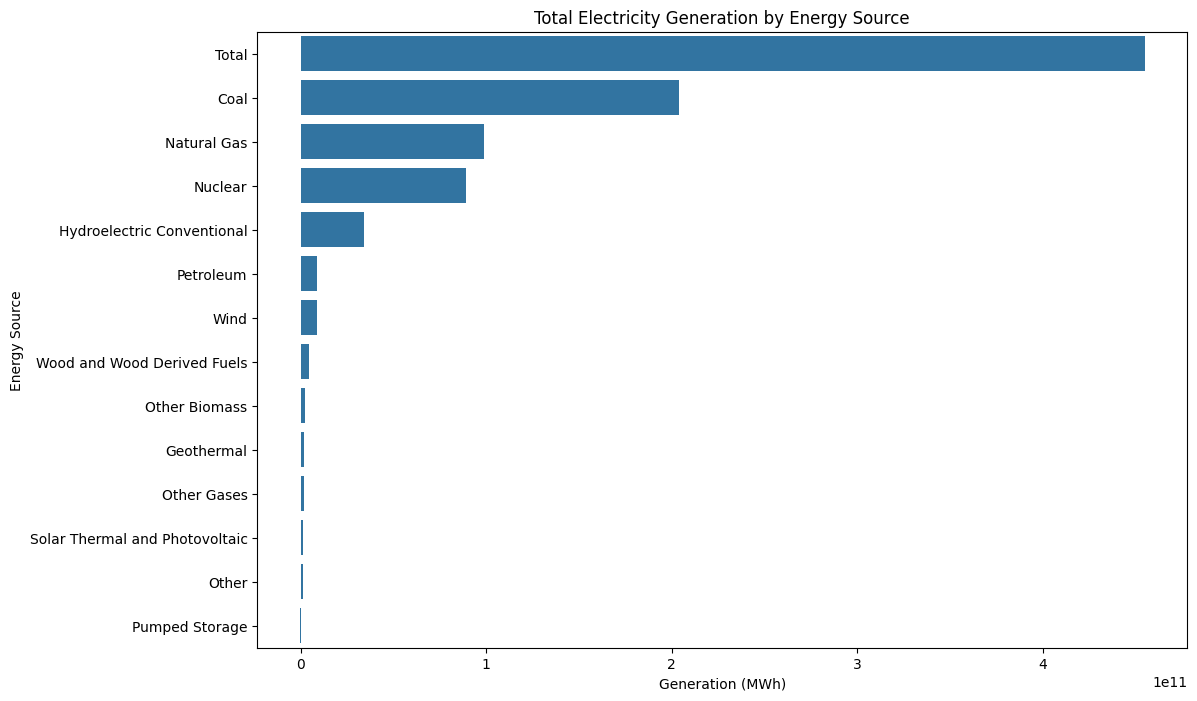

In [ ]:
plt.figure(figsize=(12,8))

sns.barplot(
    x=total_source_generation.values,
    y=total_source_generation.index
)

plt.title("Total Electricity Generation by Energy Source")
plt.xlabel("Generation (MWh)")
plt.ylabel("Energy Source")
plt.show()

TASK 7 — YEARLY ENERGY ANALYSIS


Task 7.1 — Total Energy Generation by Year

In [ ]:
yearly_generation = (
    energy
    .groupby("Year")["Generation_MWh"]
    .sum()
    .reset_index()
)

display(yearly_generation)

,Year,Generation_MWh
0,1990,2.430262e+10
1,1991,2.459039e+10
2,1992,2.467106e+10
3,1993,2.557753e+10
4,1994,2.598018e+10
5,1995,2.682790e+10
6,1996,2.755350e+10
7,1997,2.793738e+10
8,1998,2.896236e+10
9,1999,2.955848e+10


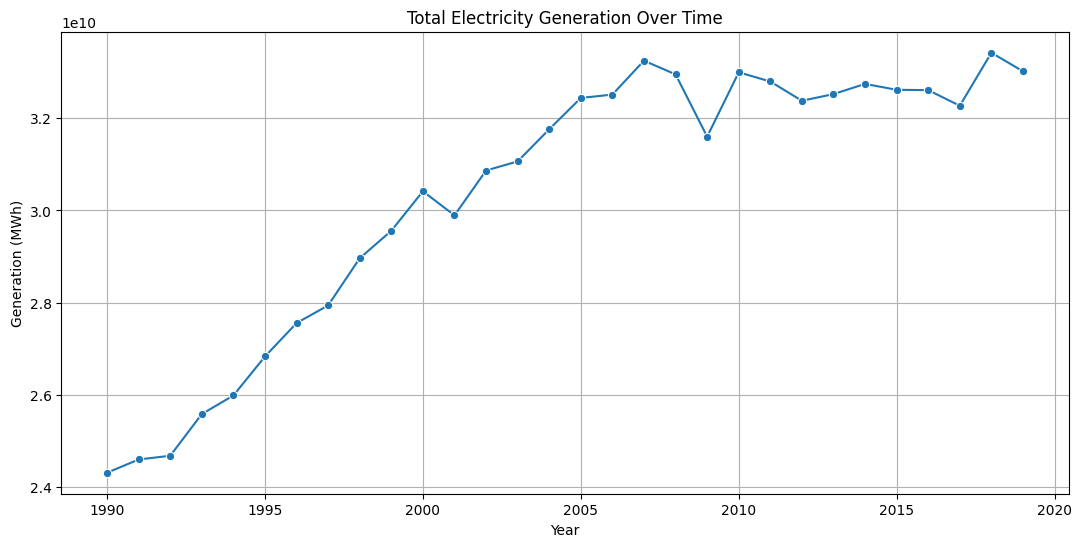

In [ ]:
plt.figure(figsize=(13,6))

sns.lineplot(
    data=yearly_generation,
    x="Year",
    y="Generation_MWh",
    marker="o"
)

plt.title("Total Electricity Generation Over Time")
plt.xlabel("Year")
plt.ylabel("Generation (MWh)")
plt.grid(True)
plt.show()

TASK 7.2 — Energy Generation Heatmap

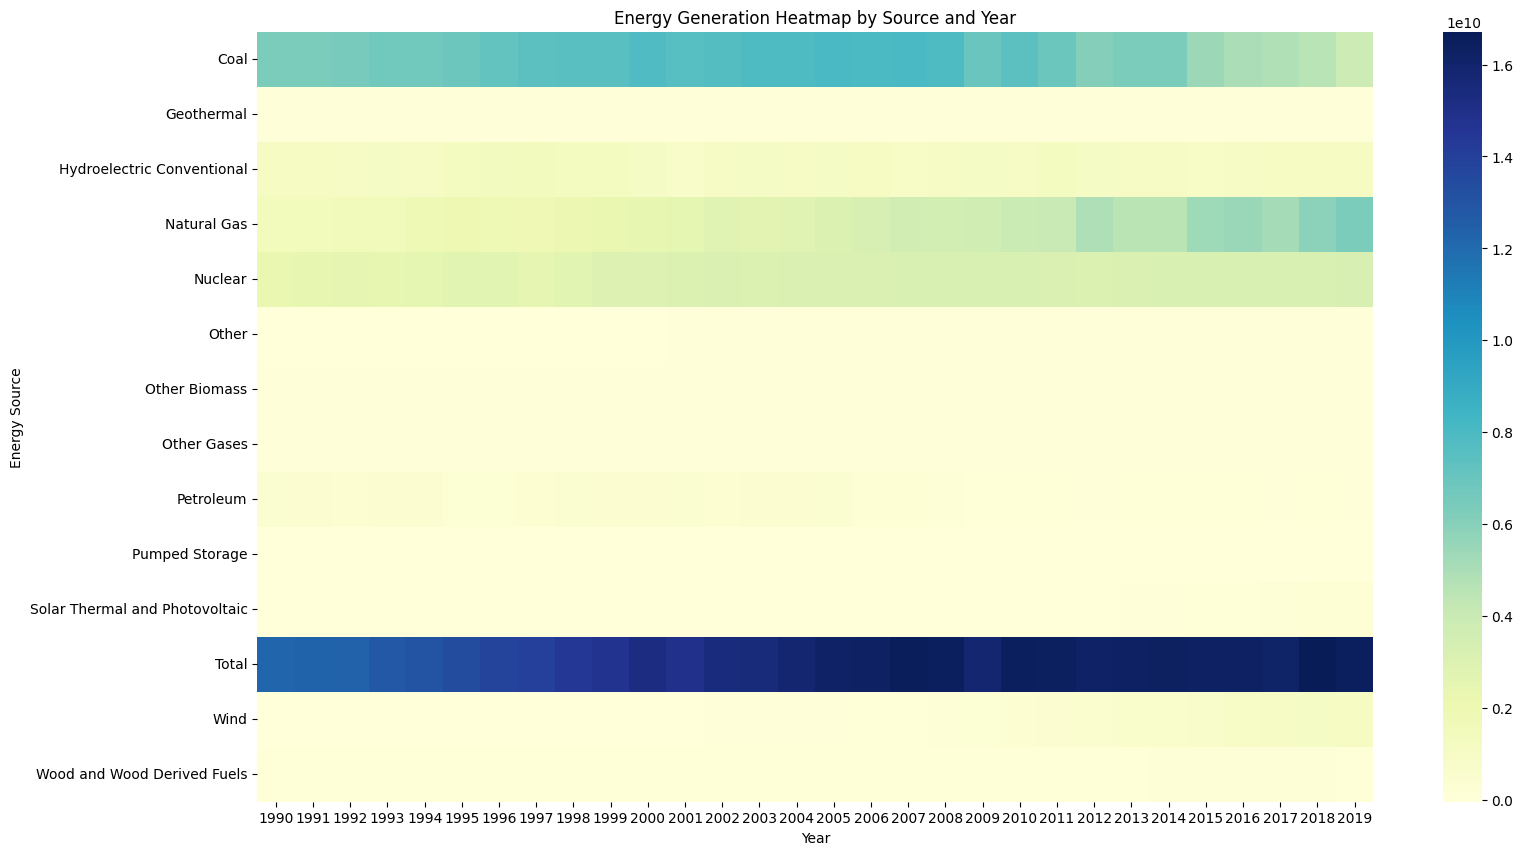

In [ ]:
energy_pivot = energy.pivot_table(
    index="Energy_Source",
    columns="Year",
    values="Generation_MWh",
    aggfunc="sum"
)

plt.figure(figsize=(18,10))

sns.heatmap(
    energy_pivot,
    cmap="YlGnBu"
)

plt.title("Energy Generation Heatmap by Source and Year")
plt.xlabel("Year")
plt.ylabel("Energy Source")
plt.show()

TASK 8 — TOP STATES ANALYSIS


Task 8.1 — Top States by EV Registration

In [ ]:

top_ev_states = (
    ev.sort_values(
        "EV_Registrations",
        ascending=False
    )
    .head(10)
)

display(top_ev_states)


,State,EV_Registrations
4,California,256800
47,Washington,28400
9,Florida,25200
43,Texas,22600
32,New York,16600
10,Georgia,15300
2,Arizona,15000
37,Oregon,12400
13,Illinois,12400
30,New Jersey,12100


Task 8.2 — Bottom States by EV Registration

In [ ]:
bottom_ev_states = (
    ev.sort_values(
        "EV_Registrations",
        ascending=True
    )
    .head(10)
)

display(bottom_ev_states)

,State,EV_Registrations
50,Wyoming,170
34,North Dakota,170
48,West Virginia,230
41,South Dakota,260
24,Mississippi,390
26,Montana,500
3,Arkansas,520
1,Alaska,530
39,Rhode Island,600
7,Delaware,720


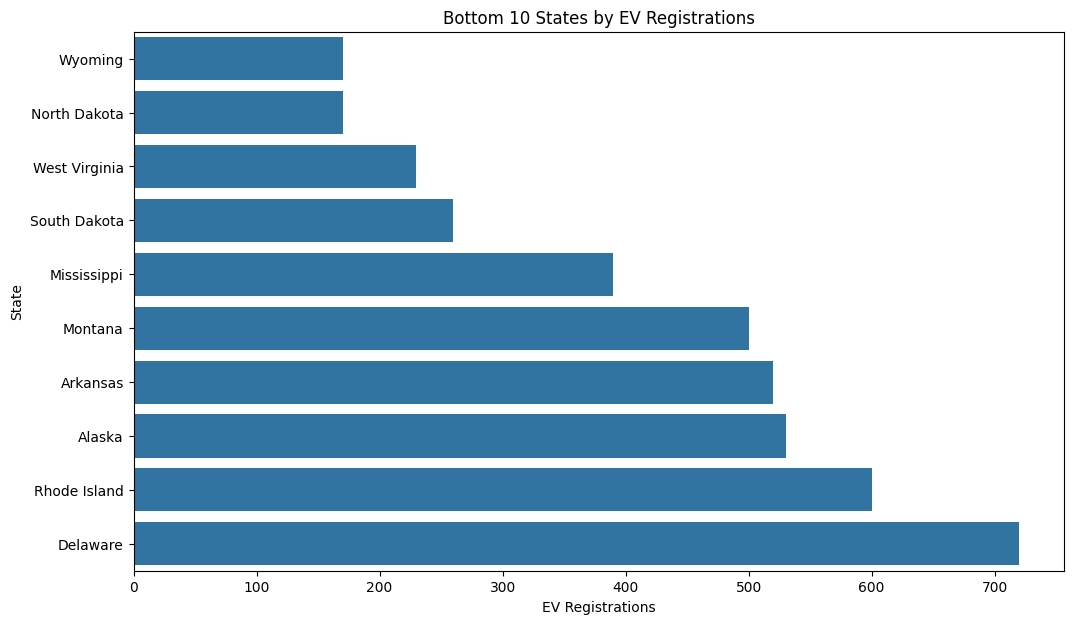

In [ ]:
plt.figure(figsize=(12,7))

sns.barplot(
    data=bottom_ev_states,
    x="EV_Registrations",
    y="State"
)

plt.title("Bottom 10 States by EV Registrations")
plt.xlabel("EV Registrations")
plt.ylabel("State")
plt.show()

TASK 8.3 — EV Distribution

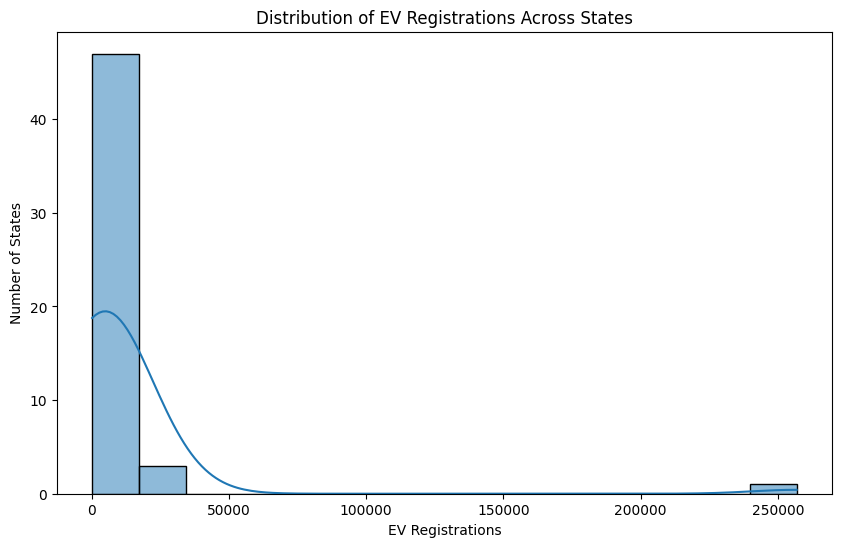

In [ ]:
plt.figure(figsize=(10,6))

sns.histplot(
    ev["EV_Registrations"],
    bins=15,
    kde=True
)

plt.title("Distribution of EV Registrations Across States")
plt.xlabel("EV Registrations")
plt.ylabel("Number of States")
plt.show()

TASK 8.4 — EV Outlier Detection

In [ ]:
Q1 = ev["EV_Registrations"].quantile(0.25)
Q3 = ev["EV_Registrations"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = ev[
    (ev["EV_Registrations"] < lower_limit) |
    (ev["EV_Registrations"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

print("\nOutlier States:")
display(outliers)

Q1: 1015.0
Q3: 8225.0
IQR: 7210.0
Lower Limit: -9800.0
Upper Limit: 19040.0

Outlier States:


,State,EV_Registrations
4,California,256800
9,Florida,25200
43,Texas,22600
47,Washington,28400


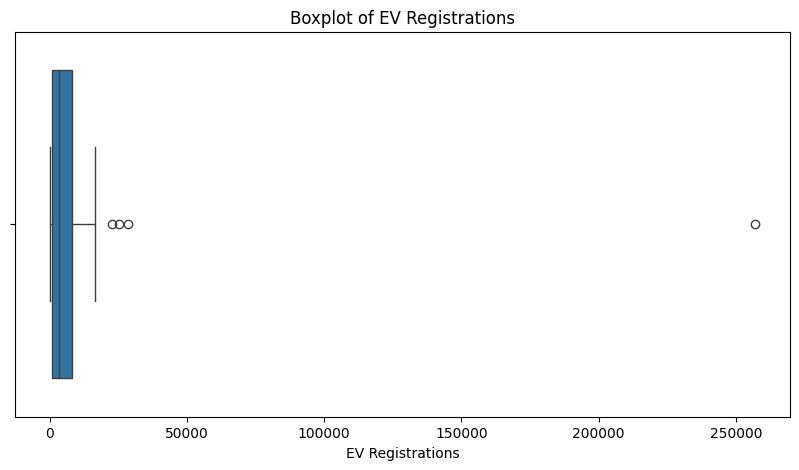

In [ ]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x=ev["EV_Registrations"]
)

plt.title("Boxplot of EV Registrations")
plt.xlabel("EV Registrations")
plt.show()

TASK 9 — FINAL EDA SUMMARY

Important Statistics

In [ ]:
print("Total EV Registrations:",
      ev["EV_Registrations"].sum())

print("Average EV Registrations per State:",
      ev["EV_Registrations"].mean())

print("Maximum EV Registrations:",
      ev["EV_Registrations"].max())

print("Minimum EV Registrations:",
      ev["EV_Registrations"].min())

print("Number of States:",
      ev["State"].nunique())

Total EV Registrations: 543610
Average EV Registrations per State: 10659.019607843138
Maximum EV Registrations: 256800
Minimum EV Registrations: 170
Number of States: 51


TASK 10 — FINAL CONCLUSION CODE

In [ ]:
print("========== FINAL EDA CONCLUSION ==========")

print(
    "1. The EV dataset contains state-level electric vehicle registrations for 2018."
)

print(
    "2. EV registrations vary considerably between states."
)

print(
    "3. The EV and total vehicle analysis helps understand EV adoption relative to the overall vehicle population."
)

print(
    "4. Renewable energy generation was analyzed using hydroelectric, wind, biomass, geothermal and solar sources."
)

print(
    "5. The energy dataset provides annual electricity generation data from 1990 to 2019."
)

print(
    "6. Wind and solar generation can be studied separately to understand the development of renewable energy over time."
)

print(
    "7. Correlation and scatter plots help identify relationships between EV registrations, vehicle registrations and renewable energy generation."
)

print(
    "8. These EDA results can be used as a starting point for further statistical analysis and policy-related investigation."
)

========== FINAL EDA CONCLUSION ==========
1. The EV dataset contains state-level electric vehicle registrations for 2018.
2. EV registrations vary considerably between states.
3. The EV and total vehicle analysis helps understand EV adoption relative to the overall vehicle population.
4. Renewable energy generation was analyzed using hydroelectric, wind, biomass, geothermal and solar sources.
5. The energy dataset provides annual electricity generation data from 1990 to 2019.
6. Wind and solar generation can be studied separately to understand the development of renewable energy over time.
7. Correlation and scatter plots help identify relationships between EV registrations, vehicle registrations and renewable energy generation.
8. These EDA results can be used as a starting point for further statistical analysis and policy-related investigation.
